# 08 — Hybrid model: CNN3 features + RBF SVM (Phase v2/04)

CNN3 beat the best classical model (`rbf_svm_hog`, 91.08%) with 92.09%, but it changed two things at once: the
**features** (learned instead of HOG) and the **classifier** (a softmax layer instead of an RBF SVM). Here we keep
CNN3 frozen, take its last hidden layer (128 numbers per image) as a third feature set, and train the Phase 1 RBF SVM on
it with exactly the Phase 1 protocol (D-044):

| Comparison | Same | Different |
|---|---|---|
| `rbf_svm_hog` vs `rbf_svm_cnn` | classifier (RBF SVM) | features (HOG vs learned) |
| `cnn3_images` vs `rbf_svm_cnn` | features (CNN3's 128) | classifier (softmax vs RBF SVM) |

**RQ9:** does an RBF SVM on CNN3's features beat CNN3's own softmax head?

Protocol (same as `rbf_svm_pixels` / `rbf_svm_hog`): tune C × gamma on a stratified 10k train subset, scored on val →
refit the chosen parameters on all 54k train images and score on val (D-029) → refit on 60k and test **once**.
Every cell reuses saved results if they exist, so re-running this notebook never re-tests.

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd() if (pathlib.Path.cwd() / "src").exists() else pathlib.Path.cwd().parent
sys.path.insert(0, str(ROOT))

import json, math, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from IPython.display import display

from src import config, features, results
from src.cnn import extract_cnn_features, load_trained
from src.data import load_splits
from src.experiment import final_test_run, full_train_val_score, tune_on_val
from src.models_tree_kernel import RBF_SVM_GRID, make_rbf_svm
from src.utils import set_seed

set_seed()
EXP = "rbf_svm_cnn"
metrics = lambda exp, kind: json.loads((config.METRICS_DIR / f"{exp}_{kind}.json").read_text())

## 1. The CNN features

`extract_cnn_features()` runs CNN3 with dropout off and stops before the last two layers (Dropout, Linear(128, 10)), so
each image becomes the 128 ReLU activations that CNN3's softmax head sees. Check: CNN3's own head applied to these
features must give CNN3's val accuracy (0.9308). The cell also times the extraction, which is part of the hybrid's
end-to-end cost (like HOG extraction in Phase 1). It needs the CNN3 checkpoint from notebook 06 (gitignored).

In [2]:
checkpoint = config.MODELS_DIR / "cnn3_images_best.pt"
if checkpoint.exists():
    cnn3 = load_trained("cnn3")
    F_val, y_val = features.get_features("cnn", "val"), features.get_labels("val")
    head_acc = (cnn3[-1](torch.from_numpy(F_val)).argmax(1).numpy() == y_val).mean()
    print("features:", F_val.shape, F_val.dtype, f"| share of zeros (ReLU): {(F_val == 0).mean():.1%}")
    print(f"CNN3's own head on these features: val acc {head_acc:.4f} (CNN3 val acc: 0.9308)")

    X_val = load_splits(verbose=False)["X_val"]
    extract_cnn_features(cnn3, X_val)  # warm-up run, not timed
    times = []
    for _ in range(3):  # best of 3, like evaluate()
        t0 = time.perf_counter(); extract_cnn_features(cnn3, X_val); times.append(time.perf_counter() - t0)
    extract_ms = min(times) / len(X_val) * 1000 * 1000
    print(f"CNN3 feature extraction: {extract_ms:.0f} ms per 1,000 images")
else:
    extract_ms = None
    print(f"{checkpoint.name} not found: skipped (saved results below are still shown). See D-041 to recreate it.")

features: (6000, 128) float32 | share of zeros (ReLU): 77.5%
CNN3's own head on these features: val acc 0.9308 (CNN3 val acc: 0.9308)


CNN3 feature extraction: 118 ms per 1,000 images


## 2. Tuning on validation (10k train subset, Phase 1 grid) ⏱ ~1 min

Same grid and subset as Phase 1's RBF SVMs: C ∈ {0.1, 1, 10}, gamma ∈ {scale, 0.01, 0.001}. Features are standardised
inside the Pipeline (D-004).

In [3]:
val_path = config.METRICS_DIR / f"{EXP}_val.json"
if not val_path.exists():
    tune_on_val("rbf_svm", make_rbf_svm, RBF_SVM_GRID, "cnn", train_subset=config.SVM_TUNE_SUBSET)
val = metrics(EXP, "val")
display(pd.DataFrame([{**r["params"], "val_acc": r["val_acc"], "val_macro_f1": r["val_macro_f1"], "fit_s": r["fit_s"]}
                      for r in val["rows"]]))
print("chosen on val:", val["best_params"], "| val acc", val["best_val_acc"])

,C,gamma,val_acc,val_macro_f1,fit_s
0,0.1,scale,0.9253,0.9252,0.54
1,0.1,0.01,0.9247,0.9246,0.54
2,0.1,0.001,0.9148,0.9148,1.32
3,1.0,scale,0.9292,0.9291,0.26
4,1.0,0.01,0.9288,0.9288,0.23
5,1.0,0.001,0.9260,0.9259,0.42
6,10.0,scale,0.9287,0.9289,0.21
7,10.0,0.01,0.9287,0.9289,0.20
8,10.0,0.001,0.9290,0.9290,0.21


chosen on val: {'C': 1, 'gamma': 'scale'} | val acc 0.9292


## 3. Chosen parameters refit on all 54k train images, scored on val (D-029) ⏱ ~1 min

This is the validation number that is comparable with CNN3 and with the other RBF SVMs.

In [4]:
if not (config.METRICS_DIR / f"{EXP}_val_full.json").exists():
    full_train_val_score("rbf_svm", make_rbf_svm, val["best_params"], "cnn")
val_table = pd.DataFrame([{"experiment": e, "val_acc": results.comparable_val_acc(e)}
                          for e in ["rbf_svm_pixels", "rbf_svm_hog", "cnn3_images", EXP]]).set_index("experiment")
display(val_table)

,val_acc
experiment,
rbf_svm_pixels,0.9082
rbf_svm_hog,0.9157
cnn3_images,0.9308
rbf_svm_cnn,0.9313


## 4. One test run ⏱ ~1 min

All choices are made. `final_test_run()` refits on all 60k (train + val) CNN features and evaluates once on test. CNN3's
weights never change: val images were only used for its early stopping, never to update weights.

In [5]:
test_path = config.METRICS_DIR / f"{EXP}_test.json"
if not test_path.exists():
    final_test_run("rbf_svm", make_rbf_svm, val["best_params"], "cnn")
test_log = pd.read_csv(config.TEST_LOG_PATH)
print(f"test_log.csv: {len(test_log)} rows; {EXP} tested {int((test_log['experiment'] == EXP).sum())} time(s)")

summary_all = results.build_summary(results.MODEL_ORDER, "summary_all.csv", results.FEATURE_ORDER)
print("summary.csv (Phase 1) still has", len(pd.read_csv(config.RESULTS_DIR / "summary.csv")), "rows")

test_log.csv: 15 rows; rbf_svm_cnn tested 1 time(s)
saved results/summary_all.csv (15 experiments)
summary.csv (Phase 1) still has 12 rows


## 5. Comparison: same classifier, same features

Wilson 95% confidence intervals for accuracy; McNemar's test (with continuity correction) on the images where two
models disagree, as in the report. "Tops confusions share" = share of errors where both the true and the predicted
class are tops (T-shirt/top, Pullover, Coat, Shirt). End-to-end time adds the feature
extraction to the classifier's prediction time (HOG: 216 ms per 1,000 images, from notebook 02).

In [6]:
y_test = load_splits(verbose=False)["y_test"]
TOPS = [0, 2, 4, 6]
COMPARE = ["rbf_svm_pixels", "rbf_svm_hog", "cnn3_images", EXP]

def wilson(k, n, z=1.96):
    p, d = k / n, 1 + z**2 / n
    centre, half = (p + z**2 / (2 * n)) / d, z * math.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / d
    return f"{(centre - half) * 100:.2f}–{(centre + half) * 100:.2f}"

rows = []
for e in COMPARE:
    t = metrics(e, "test")
    y_pred = np.asarray(t["y_pred"])
    wrong = y_pred != y_test
    rows.append({"experiment": e, "test_acc": t["accuracy"], "95% CI (%)": wilson(int((~wrong).sum()), len(y_test)),
                 "macro_f1": t["macro_f1"], "errors": int(wrong.sum()),
                 "shirt_recall": t["per_class_recall"][6],
                 "tops_confusions_share": round(float((np.isin(y_test, TOPS) & np.isin(y_pred, TOPS))[wrong].mean()), 3),
                 "predict_ms_per_1000": t["inference_ms_per_1000"], "size_MB": round(t["model_size_bytes"] / 1e6, 2)})
compare = pd.DataFrame(rows).set_index("experiment")
display(compare)

,test_acc,95% CI (%),macro_f1,errors,shirt_recall,tops_confusions_share,predict_ms_per_1000,size_MB
experiment,,,,,,,,
rbf_svm_pixels,0.8970,89.09–90.28,0.8967,1030,0.710,0.646,4766.94,125.14
rbf_svm_hog,0.9108,90.51–91.62,0.9108,892,0.752,0.642,28876.96,366.21
cnn3_images,0.9209,91.54–92.60,0.9208,791,0.751,0.681,94.43,0.97
rbf_svm_cnn,0.9244,91.91–92.94,0.9241,756,0.738,0.689,491.23,8.72


In [7]:
def mcnemar(a, b):
    g = results.model_agreement(a, b)
    only_a_right, only_b_right = g["only_b_incorrect"], g["only_a_incorrect"]
    chi2 = (abs(only_a_right - only_b_right) - 1) ** 2 / (only_a_right + only_b_right)
    return {"A": a, "B": b, "only A right": only_a_right, "only B right": only_b_right, "both wrong": g["both_incorrect"],
            "same wrong label": g["same_wrong_label"], "chi2": round(chi2, 2), "p": float(f"{math.erfc(math.sqrt(chi2 / 2)):.2g}")}

display(pd.DataFrame([mcnemar(EXP, "cnn3_images"), mcnemar(EXP, "rbf_svm_hog"), mcnemar("cnn3_images", "rbf_svm_hog")]))

,A,B,only A right,only B right,both wrong,same wrong label,chi2,p
0,rbf_svm_cnn,cnn3_images,110,75,681,659,6.25,1.200000e-02
1,rbf_svm_cnn,rbf_svm_hog,430,294,462,389,25.17,5.200000e-07
2,cnn3_images,rbf_svm_hog,417,316,475,398,13.64,2.200000e-04


In [8]:
shirts = y_test == 6
right = {e: np.asarray(metrics(e, "test")["y_pred"]) == y_test for e in [EXP, "cnn3_images"]}
print("Of 1,000 test shirts:",
      f"both right {int((right[EXP] & right['cnn3_images'] & shirts).sum())},",
      f"only hybrid {int((right[EXP] & ~right['cnn3_images'] & shirts).sum())},",
      f"only CNN3 {int((~right[EXP] & right['cnn3_images'] & shirts).sum())},",
      f"neither {int((~right[EXP] & ~right['cnn3_images'] & shirts).sum())}")

svm_ms = metrics(EXP, "test")["inference_ms_per_1000"]
if extract_ms is not None:
    print(f"End to end per 1,000 images: CNN3 features {extract_ms:.0f} ms + SVM {svm_ms:.0f} ms = {extract_ms + svm_ms:.0f} ms "
          f"(CNN3 alone: {metrics('cnn3_images', 'test')['inference_ms_per_1000']:.0f} ms)")
sv = metrics(EXP, "test")["model_size_detail"]
print(f"Hybrid size: SVM {sv['value']:,} support vectors ({compare.loc[EXP, 'size_MB']} MB) + CNN3 feature layers")

Of 1,000 test shirts: both right 719, only hybrid 19, only CNN3 32, neither 230
End to end per 1,000 images: CNN3 features 118 ms + SVM 491 ms = 609 ms (CNN3 alone: 94 ms)
Hybrid size: SVM 7,919 support vectors (8.72 MB) + CNN3 feature layers


saved results/figures/hybrid_recall_vs_cnn3.png


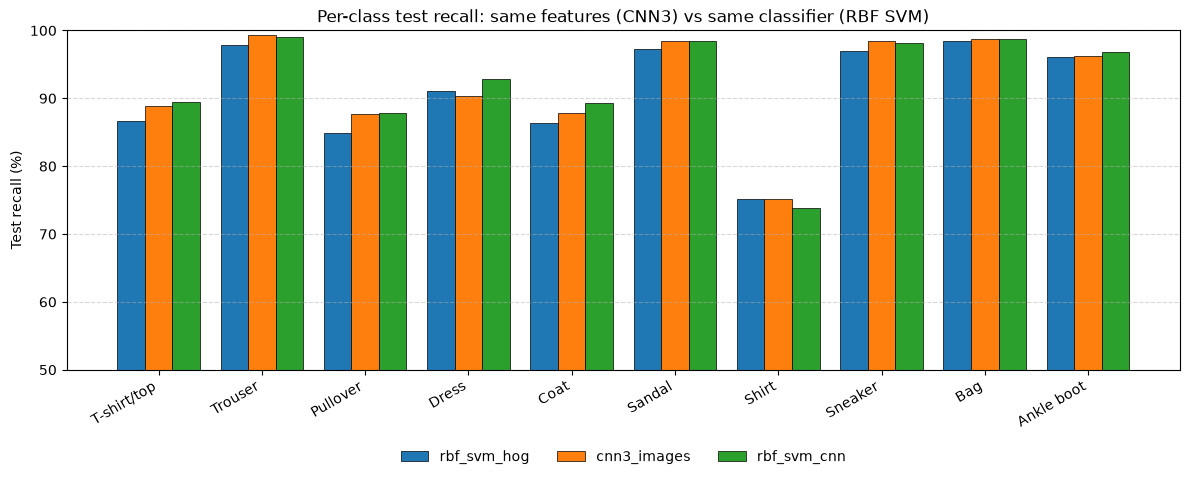

In [9]:
fig = results.plot_recall_comparison(["rbf_svm_hog", "cnn3_images", EXP], name="hybrid_recall_vs_cnn3",
                                     title="Per-class test recall: same features (CNN3) vs same classifier (RBF SVM)")
plt.show()

## 6. Answer to RQ9

| | `rbf_svm_hog` | `cnn3_images` | **`rbf_svm_cnn`** |
|---|---|---|---|
| Comparable val accuracy | 0.9157 | 0.9308 | **0.9313** |
| Test accuracy (95% CI) | 91.08% (90.51–91.62) | 92.09% (91.54–92.60) | **92.44% (91.91–92.94)** |
| Macro F1 | 0.9108 | 0.9208 | **0.9241** |
| Test errors | 892 | 791 | **756** |
| Shirt recall | 75.2% | 75.1% | 73.8% |
| End-to-end time per 1,000 images | ~29.1 s | 94 ms | ~0.6 s |
| Size | 366 MB (26,343 SVs) | 0.97 MB | 8.7 MB (7,919 SVs) + CNN3 layers |

- **Yes, slightly.** On the same 128 CNN3 features, the RBF SVM makes 35 fewer test errors than CNN3's softmax head
  (92.44% vs 92.09%). McNemar: 110 images only the hybrid gets right vs 75 only CNN3 gets right, χ² = 6.25,
  p = 0.012. On validation the two are tied (0.9313 vs 0.9308), so the gain is small and should be read with care:
  one training run, and the hybrid's SVM was refit on all 60k images while CNN3's head learned from 54k (D-044).
- **The features do most of the work.** Same classifier, different features: `rbf_svm_cnn` vs `rbf_svm_hog` is
  +1.36 points (430 vs 294 images, p = 5.2 × 10⁻⁷), about four times the head's +0.35 points. Learned features, not
  the softmax layer, are what moved Phase 2 past Phase 1.
- **Shirt is still not fixed.** The hybrid's Shirt recall is 73.8%, lower than both (Shirt → T-shirt/top: 117 vs
  CNN3's 110). Its gains are on Dress (+2.5 points over CNN3) and Coat (+1.5). Confusions among the four tops are now
  68.9% of its errors (CNN3 68.1%, SVM 64.2%). The hybrid and CNN3 share 681 errors, 659 with the same wrong label:
  a different classifier on the same features makes almost the same mistakes, which supports Phase 2's conclusion that
  the remaining errors are a limit of the 28×28 images, not of the features or the classifier.
- **Cost.** The SVM on 128 features is far cheaper than on 1,728 HOG features (7,919 vs 26,343 support vectors,
  ~49× faster end to end), but about 6× slower and 10× larger than CNN3 alone. The 0.35-point gain does not justify
  that for deployment; CNN3 stays the recommended model, and the hybrid is the most accurate model in this study.